# Projeto final – Algoritmos para Ciência de Dados (MECAI ICMC USP)

## Consulta e manutenção de anúncios do Airbnb em Lisboa

Integrantes:
- Alexandre dos Santos Gualberto – nº USP 17439272
- Luiz Venâncio Jaldin de Oliveira – nº USP 10408601
- Alessandro Melo de Oliveira – nº USP 10788662

Como rodar: abrir este notebook na pasta do projeto (a mesma do `README.md`), instalar `requirements.txt` e executar
tudo do início. Os experimentos completos levam uns 5 minutos; com `RODAR_EXPERIMENTOS = False` (seção 7) o notebook
usa os CSV de `resultados/` que vieram no zip.

In [ ]:
import os, sys, subprocess
from pathlib import Path

# no Colab: descompactar o zip e fazer %cd para a pasta projeto_final antes desta célula
RAIZ = Path.cwd()
assert (RAIZ / "airbnb").is_dir(), "rode o notebook a partir da pasta projeto_final"
sys.path.insert(0, str(RAIZ))

import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

from airbnb import (Anuncio, Repositorio, Metricas, InsertionSort, MergeSort, HeapSort, TabelaHash,
                    EstrategiaConsulta, BuscaSequencial, BuscaBinaria, BuscaInterpolacao, ConsultaHash,
                    chave_preco, chave_id)
from airbnb import dados, graficos
from airbnb.arquivos import ler_anuncios_csv, escrever_anuncios_csv
print(sys.version)

3.14.5 (main, May 10 2026, 10:21:34) [Clang 21.0.0 (clang-2100.0.123.102)]


## 1. Problema, usuários e perguntas

O usuário é uma equipe de fiscalização de alojamento local (ou de análise de mercado) de uma câmara municipal da
região de Lisboa. No dia a dia ela consulta um anúncio pelo id, que é o número do link `airbnb.com/rooms/<id>` que chega
numa denúncia ou numa lista de verificação; corrige ou retira registros; e gera relatórios ordenados por preço para ver
onde está a oferta mais cara e mais barata. A base vem das coletas do Inside Airbnb, que em 2021 foram trimestrais: a cada
coleta entram anúncios novos, saem os retirados e metade dos anúncios muda de preço.

O sistema apoia decisões como "este anúncio ainda está ativo?", "tem número de licença de alojamento local?" e "quanto
cobra comparado aos outros do município?". Uma execução é correta quando todas as estratégias de consulta devolvem o
mesmo anúncio (ou None) para o mesmo id, nenhum anúncio removido volta numa consulta, e o relatório por preço tem todos os
anúncios na mesma ordem nas três ordenações, com empate de preço desfeito pelo id.

**Pergunta operacional:** num serviço de consulta por id sobre ~20 mil anúncios que é atualizado a cada coleta, qual
estrutura de acesso usar e quando o custo de preparar e manter um índice compensa?

Perguntas experimentais, com as hipóteses escritas antes de rodar:

- P1. Até que tamanho o Insertion Sort é aceitável para o relatório por preço e como o perfil da entrada muda isso?
  H1: insertion cresce ~n² e só compete com entrada já ordenada; merge e heap crescem ~n log n, heap um pouco mais lento.
- P2. Com quantas consultas a preparação (ordenar por id ou montar a hash) se paga frente à busca sequencial?
  H2: o ponto de compensação é baixo, de poucas dezenas de consultas, porque cada sequencial custa O(n).
- P3. A interpolação ganha da binária com os ids reais do Airbnb? E se parte dos ids for de 18 dígitos, como os que o
  Airbnb usa desde 2022? H3: com ids regulares ou quase uniformes a interpolação faz 2 a 3 sondas contra ~14 da binária;
  com ids concentrados ela degrada para perto do linear.
- P4. Como o fator de carga afeta colisões e passos da hash? H4: os passos seguem 1 + α/2 (acerto) e α (erro), porque
  id mod M com M primo espalha bem os ids reais.
- P5. Com atualizações, vale mais reconstruir o índice ordenado, mantê-lo de forma incremental ou usar a hash?
  H5: atualizações intercaladas com consultas fazem a reconstrução ficar pior até que a sequencial; incremental e hash
  ficam próximas; atualizando em lote (trimestral) a escolha importa pouco.

## 2. Base de dados

Fonte: dataset "2021 Lisbon Airbnb Data" (`maurylukas/listings`) no Kaggle, licença CC BY 4.0. Ele redistribui os
arquivos `listings.csv` do Inside Airbnb (insideairbnb.com, também CC BY 4.0) da região de Lisboa em quatro coletas de
2021: mar, jun, set e dez. São dados públicos de anúncios; não usamos nome de anfitrião nem textos livres longos.

`baixar_dados.py` baixa o zip e grava em `dados/bruto/` só as 12 colunas que usamos (das 74), com todos os valores como
texto, exatamente como vieram. O bruto não é alterado; a limpeza (`airbnb/dados.py`) gera `dados/limpo/` e um log de cada
transformação.

Esquema do registro limpo:

| campo | tipo | unidade / domínio | coluna original | regra |
|---|---|---|---|---|
| id | int | ≥ 0, único, imutável | id | descarta se inválido |
| nome | str | texto do anúncio | name | vazio vira "(sem nome)" |
| bairro | str | freguesia | neighbourhood_cleansed | não vazio |
| municipio | str | 16 municípios | neighbourhood_group_cleansed | não vazio |
| tipo_quarto | str | 4 valores | room_type | fora do domínio descarta |
| preco | float | € por noite | price ("$1,234.00") | > 0, senão descarta |
| capacidade | int | hóspedes | accommodates | ≥ 1, senão descarta |
| avaliacoes | int | contagem | number_of_reviews | ≥ 0 |
| nota | float ou vazio | 0 a 5 | review_scores_rating | sem nota fica vazio |
| licenca | str ou vazio | nº de registro de alojamento local | license | sem licença fica vazio |

In [ ]:
bruto = dados.ler_bruto("mar21")
print("bruto mar/21:", bruto.shape)
dados.caracterizar(bruto)

bruto mar/21: (19804, 12)


,coluna,vazios,pct_vazios,distintos,exemplo
0,id,0,0.00,19804,6499
1,last_scraped,0,0.00,10,2021-03-11
2,name,10,0.05,19409,Belém 1 Bedroom Historical Apartment
3,host_id,0,0.00,8703,14455
4,neighbourhood_cleansed,0,0.00,128,Belm
5,neighbourhood_group_cleansed,0,0.00,16,Lisboa
6,room_type,0,0.00,4,Entire home/apt
7,price,0,0.00,491,$40.00
8,accommodates,0,0.00,17,3
9,number_of_reviews,0,0.00,429,27


In [ ]:
# problemas que aparecem no bruto
print("preço vem como texto:", bruto["price"].head(3).tolist())
for c in dados.COLETAS:
    nota = pd.to_numeric(dados.ler_bruto(c)["review_scores_rating"], errors="coerce")
    print(f"nota em {c}: min={nota.min()}, mediana={nota.median()}, max={nota.max()}")
print("bairros sem os acentos:", sorted(bruto["neighbourhood_cleansed"].unique())[27:30])
print("ids duplicados:", bruto["id"].duplicated().sum())

preço vem como texto: ['$40.00', '$30.00', '$43.00']
nota em mar21: min=20.0, mediana=95.0, max=100.0
nota em jun21: min=0.0, mediana=4.76, max=5.0


nota em sep21: min=0.0, mediana=4.76, max=5.0
nota em dec21: min=0.0, mediana=4.75, max=5.0
bairros sem os acentos: ['Beato', 'Belm', 'Benfica']
ids duplicados: 0


Três problemas reais da fonte: o preço é texto com `$` e vírgula de milhar (o valor está em euros, o Inside Airbnb usa o
símbolo `$` para qualquer moeda); a nota muda de escala entre coletas (0–100 em março, 0–5 a partir de junho); e os nomes
de bairro e município perderam as letras acentuadas no arquivo do Kaggle ("Belm" é Belém). O nome do anúncio não tem esse
problema. Abaixo, a limpeza das quatro coletas e o log da de março.

In [ ]:
coletas_df = dados.preparar_todas()          # grava dados/limpo/*.csv
limpo, log = coletas_df["mar21"]
for c, (l, _) in coletas_df.items():
    print(c, "linhas limpas:", len(l))
log

mar21 linhas limpas: 19802
jun21 linhas limpas: 19279
sep21 linhas limpas: 19103
dec21 linhas limpas: 18524


,etapa,linhas,decisao
0,entrada,19804,linhas no bruto
1,id inválido,0,descartar: sem id não há registro
2,id duplicado,0,manter a primeira ocorrência
3,nome vazio,10,imputar '(sem nome)': o resto do anúncio é válido
4,preço ausente ou <= 0,2,descartar: preço é o atributo principal
5,preço > 1000 €/noite,125,manter e sinalizar: pode ser erro do anfitrião...
6,capacidade < 1,0,descartar: anúncio para 0 hóspedes não é válido
7,tipo_quarto fora do domínio,0,descartar
8,nota em escala 0-100,16123,converter para 0-5 dividindo por 20 (mudança d...
9,"nota fora de [0,5]",0,virar ausente


Decisões: descartamos só o que não pode ser um anúncio válido (preço ≤ 0, capacidade 0). Preços acima de 1000 €/noite
(125 em março, até 20 534 €) ficam, porque podem ser casas de luxo ou erro do anfitrião e não temos como provar; eles
não atrapalham os algoritmos e nos resumos usamos mediana. Nota ausente não é imputada: anúncio sem avaliação não tem
nota. 140 anúncios têm avaliações mas não têm nota, o que é esperado (o Airbnb só mostra a nota depois de algumas
avaliações). Os 144 quase duplicados (mesmo anfitrião, nome, preço e capacidade) têm ids diferentes e são unidades
diferentes de um mesmo prédio ou hostel, então ficam. Os bairros sem acento ficam como vieram: o erro é igual nas quatro
coletas e o agrupamento continua certo.

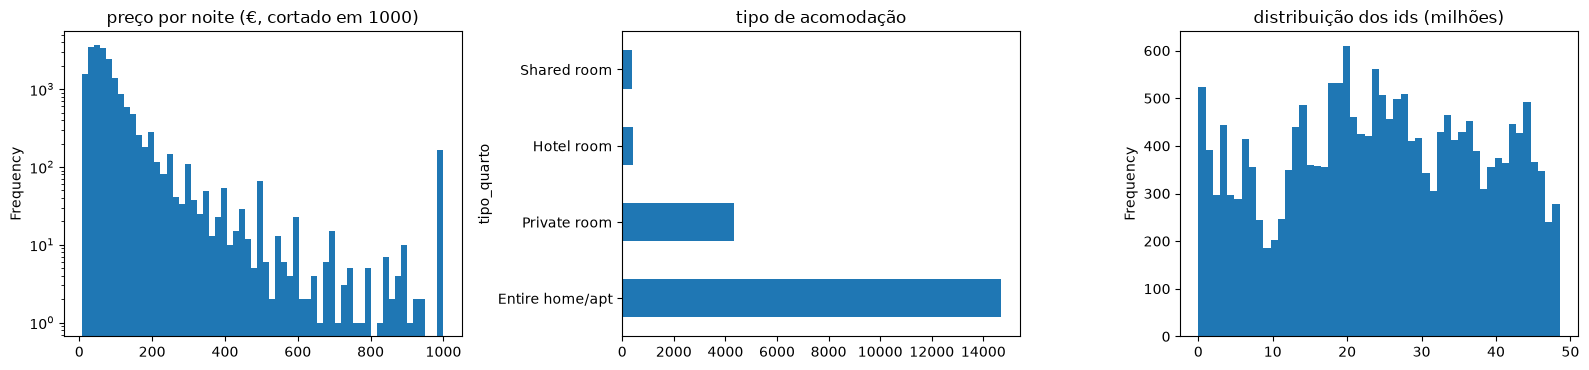

,preco,capacidade,avaliacoes,nota
count,19802.00,19802.00,19802.00,16123.00
mean,95.46,4.09,42.72,4.65
std,250.57,2.46,67.59,0.42
min,8.00,1.00,0.00,1.00
25%,40.00,2.00,2.00,4.55
50%,60.00,4.00,13.00,4.75
75%,95.00,5.00,55.00,4.90
max,20534.00,16.00,806.00,5.00


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
limpo["preco"].clip(upper=1000).plot.hist(bins=60, ax=ax[0], logy=True)
ax[0].set_title("preço por noite (€, cortado em 1000)")
limpo["tipo_quarto"].value_counts().plot.barh(ax=ax[1])
ax[1].set_title("tipo de acomodação")
(limpo["id"] / 1e6).plot.hist(bins=50, ax=ax[2])
ax[2].set_title("distribuição dos ids (milhões)")
plt.tight_layout()
plt.show()
limpo[["preco", "capacidade", "avaliacoes", "nota"]].describe().round(2)

Os ids vão de 6 499 a ~48,5 milhões e são quase uniformes nesse intervalo (o Airbnb numerou os anúncios em sequência
ao longo dos anos), o que importa para a busca por interpolação. O preço é bem assimétrico: mediana de 60 € e cauda longa.

Mudanças entre coletas (são essas as atualizações reais usadas no experimento com atualizações):

In [ ]:
linhas = []
for a, b in zip(dados.COLETAS, dados.COLETAS[1:]):
    x, y = coletas_df[a][0].set_index("id"), coletas_df[b][0].set_index("id")
    comuns = x.index.intersection(y.index)
    novos = y.index.difference(x.index)
    linhas.append({"de": a, "para": b, "saíram": len(x.index.difference(y.index)), "entraram": len(novos),
                   "novos com id menor que o maior anterior": int((novos < x.index.max()).sum()),
                   "mudaram de preço": int((x.loc[comuns, "preco"] != y.loc[comuns, "preco"]).sum())})
pd.DataFrame(linhas)

,de,para,saíram,entraram,novos com id menor que o maior anterior,mudaram de preço
0,mar21,jun21,1984,1461,660,10456
1,jun21,sep21,1773,1597,695,9772
2,sep21,dec21,1862,1283,593,10582


Cerca de 45% dos anúncios "novos" têm id menor que o maior id da coleta anterior: são anúncios antigos que voltaram ou
que não tinham sido coletados. Então inserir no fim da lista principal não mantém a lista ordenada por id.

### Resumo do domínio

In [ ]:
dados.resumo_municipios(limpo)

,anuncios,preco_mediano,pct_casa_inteira,pct_sem_licenca
municipio,,,,
Lisboa,14005,60.0,75.3,9.2
Cascais,1867,75.0,74.2,16.6
Sintra,1275,69.0,66.5,13.2
Mafra,1205,75.0,74.6,14.3
Lourinh,362,74.0,79.3,13.5
Oeiras,289,60.0,68.5,21.5
Torres Vedras,254,70.0,83.5,21.7
Loures,130,47.5,58.5,13.1
Amadora,126,35.0,46.8,16.7


In [ ]:
dados.resumo_tipos(limpo)

,count,mean,std,min,25%,50%,75%,95%,max
tipo_quarto,,,,,,,,,
Entire home/apt,14670.0,107.3,278.8,9.0,50.0,70.0,100.0,250.0,20534.0
Private room,4348.0,60.0,137.3,8.0,25.0,36.0,59.0,150.0,6041.0
Hotel room,405.0,109.8,160.9,11.0,40.0,75.0,115.0,238.4,1000.0
Shared room,379.0,30.1,57.5,8.0,14.0,18.0,24.0,88.2,887.0


Lisboa concentra 71% dos anúncios; entre os municípios com mais de 100 anúncios, Cascais, Mafra e Lourinhã são os mais caros pela mediana. Em Lisboa 9% dos anúncios não informam
licença; em Cascais 17% e em Oeiras e Torres Vedras mais de 21%. É um primeiro filtro útil para a fiscalização.

## 3. Classes e responsabilidades

```
                    +-------------------------------+
                    | Repositorio                   |   coleção principal e consistência
                    |  _registros: list[Anuncio]    |--------< Anuncio  (entidade: validação, id imutável)
                    |  _indice: TabelaHash          |   (id único; acha o registro em atualizar/remover)
                    |  _consultas: [EstrategiaConsulta]
                    +-------------------------------+
                           | avisa ao_inserir / ao_remover, reconstrói antes de buscar se inválida
                           v
        +----------------------------------+              +------------------------------+
        | EstrategiaConsulta (ABC)         |              | EstrategiaOrdenacao (ABC)    |
        |  preparar(registros, metricas)   |              |  ordenar(regs, chave, m)     |
        |  buscar(id, metricas) -> Anuncio|None            |  _ordenar_itens (abstrato)   |
        |  ao_inserir / ao_remover         |              +------------------------------+
        +----------------------------------+                 ^          ^           ^
           ^              ^                ^            InsertionSort MergeSort  HeapSort
  BuscaSequencial  _BuscaEmVetorOrdenado  ConsultaHash ---tem---> TabelaHash
                    tem uma EstrategiaOrdenacao (ordena por id na preparação)
                      ^              ^
               BuscaBinaria   BuscaInterpolacao

  ExecutorExperimentos --tem--> GeradorCargas, [EstrategiaOrdenacao], [fábricas de EstrategiaConsulta]
                       --cria por execução--> Metricas      --devolve--> [ResultadoExecucao] -> CSV
  arquivos.py: só CSV <-> Anuncio      dados.py: só pandas      graficos.py: só lê os CSV de resultados
```

Por que cada coisa está onde está:

- `Anuncio` valida os próprios campos e não deixa mudar o id (só tem property de leitura; `alterar` recusa `id` e valida
  tudo antes de aplicar, então uma alteração inválida não deixa o objeto pela metade).
- `Repositorio` é o único dono da lista de anúncios e o único que sabe quando ela muda, por isso é ele que avisa os
  índices. Ele não expõe a lista: `registros()` devolve tupla. Tem uma `TabelaHash` própria só para garantir id único e
  achar o registro em atualizar/remover; as estratégias de consulta são outra coisa e podem ser trocadas.
- As estratégias de consulta guardam referências aos mesmos objetos do repositório, nunca cópias de anúncios. Alterar
  preço ou nota não muda a posição de ninguém (os índices são por id), então não invalida nada. Inserção e remoção
  invalidam as estruturas ordenadas (ou atualizam, na versão incremental) e são repassadas para a hash.
- `_BuscaEmVetorOrdenado` recebe a ordenação por composição: a binária pode preparar com `MergeSort` ou com
  `InsertionSort` sem mudar nada no código de busca. A herança só aparece onde vale substituição: qualquer
  `EstrategiaConsulta` serve onde o repositório ou o executor esperam uma.
- `HeapSort`, `MergeSort` e `InsertionSort` compartilham o método template `ordenar` (monta pares (chave, registro),
  ordena, devolve lista nova) e só implementam o laço do algoritmo.
- `ExecutorExperimentos` recebe estratégias e gerador por composição e cria um `Metricas` novo por execução. Algoritmo não
  lê arquivo nem desenha gráfico; gráfico não roda algoritmo, só lê CSV.

Contratos dos métodos públicos (tipos anotados no código):

| método | contrato |
|---|---|
| `Repositorio.inserir(registro) -> None` | ValueError se o id já existe; senão entra na lista, no índice e avisa as estratégias |
| `Repositorio.atualizar(id, alteracoes) -> None` | KeyError se não existe; ValueError se tenta mudar id ou valor inválido |
| `Repositorio.remover(id) -> bool` | False se não existia; depois disso nenhuma estratégia devolve esse anúncio |
| `Repositorio.buscar(id, estrategia, metricas) -> Anuncio \| None` | reconstrói a estratégia se estiver inválida |
| `EstrategiaOrdenacao.ordenar(registros, chave, metricas) -> list[Anuncio]` | lista nova crescente pela chave; não altera a entrada |
| `EstrategiaConsulta.preparar(registros, metricas) -> None` | monta a estrutura; registros só leitura |
| `EstrategiaConsulta.buscar(id, metricas) -> Anuncio \| None` | RuntimeError se não preparada |
| `TabelaHash.inserir / buscar / remover` | ValueError em id repetido; buscar devolve registro ou None; remover devolve bool |
| `ExecutorExperimentos.executar(configuracao) -> list[ResultadoExecucao]` | uma medida por linha, com semente e unidade |

## 4. Demonstração do sistema

In [ ]:
repo = Repositorio([BuscaSequencial(), BuscaBinaria(), BuscaInterpolacao(), ConsultaHash()])
repo.carregar(ler_anuncios_csv("dados/limpo/anuncios_mar21.csv"))
print(len(repo), "anúncios; estratégias:", repo.nomes_consultas)

def consultar_todas(id):
    for nome in repo.nomes_consultas:
        print(f"  {nome:13s} -> {repo.buscar(id, nome)}")

print("id 6499 (existe):"); consultar_todas(6499)
print("id 6500 (não existe):"); consultar_todas(6500)

19802 anúncios; estratégias: ['sequencial', 'binaria', 'interpolacao', 'hash']
id 6499 (existe):
  sequencial    -> Anuncio(id=6499, nome='Belém 1 Bedroom Historical Apa', bairro='Belm', tipo='Entire home/apt', preco=40.00)
  binaria       -> Anuncio(id=6499, nome='Belém 1 Bedroom Historical Apa', bairro='Belm', tipo='Entire home/apt', preco=40.00)
  interpolacao  -> Anuncio(id=6499, nome='Belém 1 Bedroom Historical Apa', bairro='Belm', tipo='Entire home/apt', preco=40.00)
  hash          -> Anuncio(id=6499, nome='Belém 1 Bedroom Historical Apa', bairro='Belm', tipo='Entire home/apt', preco=40.00)
id 6500 (não existe):
  sequencial    -> None
  binaria       -> None
  interpolacao  -> None
  hash          -> None


In [ ]:
novo = Anuncio(60_000_001, "Estúdio novo no Intendente", "Arroios", "Lisboa", "Entire home/apt", 72.0, 2)
repo.inserir(novo)
try:
    repo.inserir(Anuncio(6499, "Cópia", "Belm", "Lisboa", "Private room", 30.0, 1))
except ValueError as e:
    print("duplicado rejeitado:", e)
try:
    repo.atualizar(60_000_001, {"id": 7})
except ValueError as e:
    print("id imutável:", e)
try:
    novo.alterar(preco=-5)
except ValueError as e:
    print("validação:", e, "| preço continua", novo.preco)

repo.atualizar(60_000_001, {"preco": 85.0, "nota": 4.9})
print("novo id depois da alteração:"); consultar_todas(60_000_001)
print("remover 6499:", repo.remover(6499), "| remover de novo:", repo.remover(6499))
consultar_todas(6499)
print("reconstruções:", repo.reconstrucoes)

duplicado rejeitado: id 6499 já cadastrado
id imutável: o id é imutável
validação: preço deve ser positivo, recebido -5 | preço continua 72.0
novo id depois da alteração:
  sequencial    -> Anuncio(id=60000001, nome='Estúdio novo no Intendente', bairro='Arroios', tipo='Entire home/apt', preco=85.00)
  binaria       -> Anuncio(id=60000001, nome='Estúdio novo no Intendente', bairro='Arroios', tipo='Entire home/apt', preco=85.00)
  interpolacao  -> Anuncio(id=60000001, nome='Estúdio novo no Intendente', bairro='Arroios', tipo='Entire home/apt', preco=85.00)
  hash          -> Anuncio(id=60000001, nome='Estúdio novo no Intendente', bairro='Arroios', tipo='Entire home/apt', preco=85.00)
remover 6499: True | remover de novo: False
  sequencial    -> None
  binaria       -> None
  interpolacao  -> None
  hash          -> None
reconstruções: {'sequencial': 1, 'binaria': 3, 'interpolacao': 3, 'hash': 1}


A binária e a interpolação foram reconstruídas antes da primeira consulta e depois da inserção e da remoção (preparação
preguiçosa). A hash foi preparada uma vez e depois só recebeu a inserção e a remoção. A sequencial lê a própria lista do
repositório e nunca precisa de preparação.

Relatório por preço, com id como desempate, pelas três ordenações:

In [ ]:
rel = {o.nome: repo.relatorio(o) for o in (InsertionSort(), MergeSort(), HeapSort())}
print("mesma ordem nas três:", rel["insertion"] == rel["merge"] == rel["heap"], "| tamanho:", len(rel["merge"]))
print("todos os registros preservados:", sorted(a.id for a in rel["heap"]) == sorted(a.id for a in repo))
escrever_anuncios_csv(rel["merge"], "resultados/relatorio_por_preco.csv")
pd.DataFrame([a.como_linha() for a in rel["merge"][-8:]], columns=["id", "nome", "bairro", "municipio", "tipo",
              "preco", "cap", "aval", "nota", "licenca"])

mesma ordem nas três: True | tamanho: 19802
todos os registros preservados: True


,id,nome,bairro,municipio,tipo,preco,cap,aval,nota,licenca
0,13829675,Cosy room in Intendente,Arroios,Lisboa,Private room,6041.0,2,135,4.8,
1,10362958,Turquoise Apartament,"Oeiras e S.Julio da Barra, Pao de Arcos e Caxias",Oeiras,Entire home/apt,7771.0,2,94,4.75,30077/AL
2,22055901,Apt Parque das Nações 5C -Best Apartments Port...,Parque das Naes,Lisboa,Entire home/apt,8000.0,4,1,4.0,75389/AL
3,29005131,Cantinho de Belém,Belm,Lisboa,Entire home/apt,8000.0,4,4,5.0,83400/AL
4,37074411,Divine Apartment Stúdio,Penha de Frana,Lisboa,Entire home/apt,8000.0,2,0,,60804/AL
5,38481513,Palácio Ramalhete,Estrela,Lisboa,Entire home/apt,8125.0,16,0,,
6,36762623,Penthouse with view in the City Center,Santo Antnio,Lisboa,Entire home/apt,9999.0,6,32,4.75,19804
7,31979757,Vivenda Duarte,Ericeira,Mafra,Entire home/apt,20534.0,6,6,5.0,23903/AL


O mesmo cliente com estratégias diferentes: a função abaixo só conhece o contrato `EstrategiaConsulta` e recebe
objetos de quatro classes; a binária ainda aparece com duas ordenações diferentes na preparação.

In [ ]:
def conferir_lote(consulta: EstrategiaConsulta, registros, ids) -> tuple[int, int]:
    m = Metricas()
    consulta.preparar(registros, m)
    passos_prep = m.comparacoes
    m = Metricas()
    achados = sum(consulta.buscar(i, m) is not None for i in ids)
    return achados, m.passos

regs = list(repo)
ids = [a.id for a in regs[::40]] + [a.id + 1 for a in regs[::40]]
for c in (BuscaSequencial(), BuscaBinaria(), BuscaBinaria(InsertionSort()), BuscaInterpolacao(), ConsultaHash()):
    achados, passos = conferir_lote(c, regs, ids)
    print(f"{c.rotulo:30s} achou {achados} de {len(ids)} | passos nas consultas: {passos}")

sequencial                     achou 497 de 992 | passos nas consultas: 14720688
binaria/reconstroi-merge       achou 497 de 992 | passos nas consultas: 13760
binaria/reconstroi-insertion   achou 497 de 992 | passos nas consultas: 13760
interpolacao/reconstroi-merge  achou 497 de 992 | passos nas consultas: 13458
hash                           achou 497 de 992 | passos nas consultas: 887


Tabela hash: colisão provocada (ids que diferem de um múltiplo de M caem no mesmo balde) e consulta depois de remover
um elemento do meio do balde.

In [ ]:
t = TabelaHash(11)
M = t.capacidade
a = [Anuncio(5 + k * M, f"anuncio {k}", "Ajuda", "Lisboa", "Private room", 30.0 + k, 1) for k in range(3)]
for x in a:
    t.inserir(x)
print(t, "| colisões:", t.colisoes, "| baldes:", t.tamanhos_baldes())
m = Metricas(); print("buscar", 5 + 2 * M, "->", t.buscar(5 + 2 * M, m).nome, "| comparações:", m.passos)
print("remover", 5 + M, "->", t.remover(5 + M))
m = Metricas(); print("buscar", 5 + M, "->", t.buscar(5 + M, m), "| comparações:", m.passos)
print("buscar", 5 + 2 * M, "->", t.buscar(5 + 2 * M).nome, "(continua acessível)")

TabelaHash(N=3, M=11, alfa=0.273) | colisões: 2 | baldes: [0, 0, 0, 0, 0, 3, 0, 0, 0, 0, 0]
buscar 27 -> anuncio 2 | comparações: 3
remover 16 -> True
buscar 16 -> None | comparações: 2
buscar 27 -> anuncio 2 (continua acessível)


### Heapsort passo a passo

Vetor em base 0: pai(i) = (i−1)//2, filhos 2i+1 e 2i+2. A construção bottom-up chama sift-down do último pai (n//2 − 1)
até a raiz. Em cada extração a raiz (maior) troca com o último da região ativa, a região ativa diminui um e o sift-down
refaz o heap. Abaixo, a região ativa está entre colchetes e o sufixo ordenado depois da barra.

In [ ]:
precos = [55.0, 30.0, 80.0, 12.0, 95.0, 40.0, 61.0]
pequenos = [Anuncio(i + 1, f"a{i}", "Ajuda", "Lisboa", "Private room", p, 1) for i, p in enumerate(precos)]
h = HeapSort(registrar_passos=True)
saida = h.ordenar(pequenos, chave_preco)
print("entrada:          ", precos)
for descricao, chaves, tam in h.passos[:4]:
    v = [k[0] for k in chaves]
    print(f"{descricao:18s} [{', '.join(f'{x:g}' for x in v[:tam])}] | {', '.join(f'{x:g}' for x in v[tam:])}")
    pais_ok = all(v[(i - 1) // 2] >= v[i] for i in range(1, tam))
    print(f"{'':18s} propriedade de heap na região ativa: {pais_ok}; sufixo ordenado: {v[tam:] == sorted(v[tam:])}")
print("saída:            ", [a.preco for a in saida])

entrada:           [55.0, 30.0, 80.0, 12.0, 95.0, 40.0, 61.0]
heap construída    [95, 55, 80, 12, 30, 40, 61] | 
                   propriedade de heap na região ativa: True; sufixo ordenado: True
extração 1         [80, 55, 61, 12, 30, 40] | 95
                   propriedade de heap na região ativa: True; sufixo ordenado: True
extração 2         [61, 55, 40, 12, 30] | 80, 95
                   propriedade de heap na região ativa: True; sufixo ordenado: True
extração 3         [55, 30, 40, 12] | 61, 80, 95
                   propriedade de heap na região ativa: True; sufixo ordenado: True
saída:             [12.0, 30.0, 40.0, 55.0, 61.0, 80.0, 95.0]


## 5. Complexidade e corretude

n = número de anúncios, M = número de baldes, α = n/M, Q = consultas. "Pares" é a lista de (chave, registro) que as
três ordenações montam antes de ordenar: n tuplas novas + n chaves (tuplas (preço, id)), O(n) igual para as três.

| implementação | pré-condição | melhor caso | pior caso | esperado (hipótese) | espaço auxiliar |
|---|---|---|---|---|---|
| Insertion Sort | nenhuma | Θ(n), já ordenado | Θ(n²), inverso | ~n²/4 comparações, aleatório | O(1) no vetor + pares |
| Merge Sort recursivo | nenhuma | Θ(n log n) | Θ(n log n) | Θ(n log n) | fatias O(n) por nível (liberadas) + pilha O(log n) + pares |
| Heapsort | nenhuma | Θ(n log n) (chaves distintas) | Θ(n log n) | Θ(n log n) | O(1) no vetor + pares |
| Busca sequencial | nenhuma | 1 passo | n passos (ausente) | n/2 acerto, n erro | preparação O(1), só referência à lista |
| Busca binária | vetor ordenado por id | 1 passo | ⌊log₂ n⌋+1 | ~log₂ n | cópia ordenada: n referências; preparação O(n log n) |
| Interpolação | vetor ordenado por id, ids numéricos | 1 sonda | n sondas (ids concentrados) | O(log log n) com ids uniformes | mesma cópia da binária |
| Hash encadeamento | h(id) espalha bem | 1 comparação | n (todos num balde) | 1 + α/2 acerto, α erro | M listas + n referências; preparação O(n) |
| Repositorio.inserir | — | O(1 + α) índice | + aviso às estratégias | O(1) amortizado | 1 referência na lista e 1 no índice |
| Repositorio.remover | — | O(1) se é o primeiro da lista | O(n): acha a posição e `del` desloca | O(n) | — |

Separando o que ocupa memória: os registros (objetos `Anuncio` com `__slots__`) existem uma vez só, dentro do repositório.
Índices guardam referências (8 bytes cada) mais o objeto lista: a cópia ordenada custa ~8n bytes, a hash custa uma lista
Python por balde (56 bytes vazia) mais as referências, então com α pequeno a hash gasta muito mais que a cópia ordenada.
A recursão do merge usa ⌈log₂ n⌉ quadros de pilha (15 para n = 19 802).

### Recorrência do Merge Sort

Para n > 1 o algoritmo faz duas chamadas em metades (⌈n/2⌉ e ⌊n/2⌋) e um merge que copia as duas fatias e escreve os n
elementos de volta, custo cn. Então T(1) = c e T(n) = 2T(n/2) + cn.

Desenrolando: T(n) = 2T(n/2) + cn = 4T(n/4) + 2cn = ... = 2^k T(n/2^k) + k·cn. Com k = log₂ n, T(n) = cn + cn log₂ n =
Θ(n log n). O Método Mestre dá o mesmo: a = 2 ≥ 1, b = 2 > 1, f(n) = cn = Θ(n^(log_b a)) = Θ(n¹), caso 2, logo
T(n) = Θ(n log n). As condições valem porque os subproblemas têm tamanho n/2 (o piso e o teto não mudam a ordem) e
f(n) é positiva. Como o merge é sempre Θ(n) por nível, independente da ordem da entrada, o tempo não depende do perfil.

Escolhemos Merge Sort em vez de Quick Sort porque dois dos perfis exigidos (ordenado e inverso) são o pior caso do
Quick Sort com pivô fixo: partições de tamanho 0 e n−1, T(n) = T(n−1) + cn = Θ(n²) e recursão de profundidade n, que
estoura o limite de recursão do Python (1000) já com n = 2000. Com partições equilibradas ele teria T(n) = 2T(n/2) + cn
como o merge.

### Heap: construção linear e invariantes

Na construção bottom-up o sift-down de um nó de altura h custa O(h), e um heap com n nós tem no máximo ⌈n/2^(h+1)⌉ nós de
altura h. Somando: Σ_h ⌈n/2^(h+1)⌉·O(h) = O(n · Σ_h h/2^h) = O(2n) = O(n), porque Σ h/2^h converge para 2. A maioria dos
nós está perto das folhas e desce pouco. Depois vêm n−1 extrações, cada uma com um sift-down de custo O(log n) no pior
caso, então o heapsort é O(n log n) no pior caso, e não depende da entrada.

Invariante das extrações (vale antes de cada iteração com região ativa de tamanho tam):
1. v[0..tam−1] é heap de máximo: v[(i−1)//2] ≥ v[i] para 1 ≤ i < tam;
2. v[tam..n−1] está em ordem crescente;
3. todo elemento da região ativa é ≤ todo elemento do sufixo.
Inicialização: depois da construção tam = n e o sufixo é vazio. Manutenção: a raiz é o máximo da região ativa (1), e por
(3) é ≤ ao primeiro do sufixo; trocá-la com v[tam−1] e diminuir tam estende o sufixo ordenado; o sift-down restaura (1).
Término: tam = 1, então v inteiro está ordenado.

Invariante da busca binária: se o id está em v, então está em v[ini..fim]. Vale no início (ini = 0, fim = n−1); se
v[meio].id < id, como v é crescente, o id só pode estar depois de meio (ini = meio+1); o caso contrário é simétrico.
fim − ini diminui a cada passo, então termina; quando ini > fim o intervalo é vazio e o id não está em v.

Invariante do Insertion Sort: antes da iteração j, v[0..j−1] está ordenado e tem os mesmos elementos de antes.

### Condições dos custos esperados

Hash: 1 + α/2 e α supõem hashing uniforme simples (cada id cai em qualquer balde com a mesma chance, independente dos
outros). Os ids do Airbnb não são aleatórios, mas não têm relação com um M primo, então id mod M se comporta bem; isso é
testado no experimento. Se os ids fossem múltiplos de um número com fator comum com M (por exemplo ids de 1000 em 1000 e
M = 10 000), muitos baldes ficariam vazios.

Interpolação: O(log log n) exige ids distribuídos de forma aproximadamente uniforme entre o menor e o maior. Se poucos ids
enormes esticam o intervalo, a estimativa cai sempre perto do início e cada sonda descarta poucas posições: O(n).

### Custos das operações do Python que não são gratuitas

- fatias `v[a:b]` no merge copiam b−a referências: O(b−a) tempo e memória;
- `ordenar` monta a lista de pares e a lista de saída: duas cópias O(n);
- `list.insert` e `del v[i]` deslocam o resto da lista: O(n), usados na versão incremental e na remoção do repositório;
- `registros()` devolve `tuple(...)`: O(n) a cada chamada;
- comparar tuplas (preço, id) compara campo a campo; com preços repetidos compara também o id;
- a recursão do merge cria um quadro de função por chamada (2n−1 chamadas no total);
- acessar `r.id` é chamada de property, mais cara que ler um campo de lista.

### Custo do sistema ao longo do uso

Num lote estático de Q consultas: T_total(Q) = T_preparação + Q · T_consulta. A sequencial tem T_preparação ≈ 0 e
T_consulta = Θ(n); as outras pagam a preparação uma vez e têm T_consulta pequeno. O ponto de compensação contra a
sequencial é Q* = T_preparação / (T_consulta_seq − T_consulta_x). Com atualizações o custo passa a ser a soma das consultas
mais a manutenção de cada inserção/remoção mais (número de reconstruções) × T_preparação. Reconstruir preguiçosamente
paga T_preparação a cada vez que uma consulta vem depois de uma mudança estrutural.

## 6. Testes

`tests/test_sistema.py` (pytest) cobre: validação do `Anuncio` e id imutável; alteração atômica; CSV ida e volta (com
aspas e vírgula no nome); as três ordenações iguais a `sorted` em base vazia, 1, 2, 57 e 300 registros com muitos
empates; empate desfeito pelo id; perfis ordenado e inverso; não alterar a entrada e preservar todos os objetos;
propriedade de heap depois da construção; hash com colisão deliberada, remoção no meio do balde, consulta após remoção,
id duplicado, fator de carga e rehash; as quatro consultas concordando (mesmo objeto) em base vazia, 1, 2 e 500
registros, com ids presentes, ausentes, negativos e fora do intervalo; interpolação com ids concentrados; o mesmo cliente
recebendo as quatro estratégias; repositório vazio, com um registro, rejeitando duplicado e alteração de id, e consistente
depois de remoções, inserções e alterações (nenhum removido volta, nº de reconstruções certo); manutenção incremental;
relatório igual nas três ordenações.

In [ ]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", "tests"], capture_output=True, text=True, cwd=RAIZ)
print(r.stdout[-1500:], r.stderr[-1500:])

...........................                                              [100%]
27 passed in 0.15s
 


## 7. Protocolo experimental

Tudo roda em `rodar_experimentos.py` (que este notebook chama), com semente 2024 e configuração gravada em
`resultados/ambiente.txt`. Cada configuração tem 5 repetições; a repetição r usa a semente 2024 + 1000r + n para sortear a
amostra, então todas as estratégias recebem exatamente a mesma entrada. Os tempos são `time.perf_counter_ns` (ns), com o
coletor de lixo desligado durante a medição; geração da entrada, cópia e validação ficam fora. Antes de medir há uma
rodada de aquecimento não contada. As contagens (comparações, movimentações, passos) e a memória (`tracemalloc`, pico de
bytes alocados pelo Python durante a chamada) são medidas em execuções separadas, na repetição 0, porque os contadores
mudam o tempo. `tracemalloc` só vê alocações feitas dentro da chamada (cópias, listas auxiliares, tabela), não os
anúncios que já existiam, e não vê memória de C fora do alocador do Python. Os resultados são CSV em formato longo:
experimento, estratégia, n, perfil, parâmetro, repetição, semente, medida, valor e unidade. Reportamos mediana e IQR.

| experimento | configuração |
|---|---|
| ordenação | n = 500, 2000, 8000 (fator 4); perfis aleatório, ordenado, inverso e repetições (só 5 preços distintos); chave (preço, id) |
| buscas | n = 2000, 6000, 18000 (fator 3); ids regulares (1000, 2000, ...), reais e concentrados (10% com ids de 18 dígitos); lote de 2000 consultas, 50% presentes e 50% ausentes (ausente = id existente ± até 500) |
| hash | base inteira de mar/21 (19 802), α = 0,25, 0,50, 0,75 e também 1 e 2; M = primo ≥ N/α; sem rehash |
| lote estático | base inteira, Q = 1, 10, 100, 1000, 10 000; tempo de preparar + responder o lote |
| com atualizações | base mar/21; trimestral: 1000 consultas, depois as remoções, inserções e mudanças de preço reais para a próxima coleta, 3 vezes, e mais 1000 consultas; intercalado: 4000 operações sorteadas, 80% consulta, 10% alteração de preço, 5% inserção (anúncios de coletas posteriores), 5% remoção. Mesma sequência para todas as estratégias |
| referências nativas | `sorted`, `dict` e `sorted`+`bisect`, fora do núcleo, só para comparação |

No cenário com atualizações comparamos seis estratégias: sequencial; binária que reconstrói com Merge Sort; binária que
reconstrói com Insertion Sort (a lista principal fica quase ordenada por id); binária incremental; interpolação
incremental; e hash. As respostas de todas são comparadas consulta a consulta.

In [ ]:
RODAR_EXPERIMENTOS = True    # False: usa os CSV de resultados/ que vieram no zip

if RODAR_EXPERIMENTOS:
    import rodar_experimentos
    rodar_experimentos.executar_tudo()
print(open("resultados/ambiente.txt", encoding="utf-8").read())

ordenacao: 348 medidas em 61 s


busca: 972 medidas em 57 s


hash: 100 medidas em 3 s


lote: 150 medidas em 27 s


misto: 420 medidas em 113 s
divergências: nenhuma
python: 3.14.5
implementacao: CPython
sistema: macOS-27.0-arm64-arm-64bit-Mach-O
processador: arm
cpus: 8
pandas: 3.1.1
numpy: 2.5.5
matplotlib: 3.11.2
semente: 2024
repeticoes: 5
config: {'ordenacao': {'tamanhos': (500, 2000, 8000), 'perfis': ('aleatorio', 'ordenado', 'inverso', 'repeticoes')}, 'busca': {'tamanhos': (2000, 6000, 18000), 'perfis': ('regular', 'real', 'concentrada'), 'q': 2000}, 'hash': {'alfas': (0.25, 0.5, 0.75, 1.0, 2.0), 'q': 20000}, 'lote': {'qs': (1, 10, 100, 1000, 10000)}, 'misto': {'q_trimestral': 1000, 'n_ops_intercalado': 4000, 'proporcoes': (0.8, 0.1, 0.05, 0.05)}}
sequencia trimestral: {'consulta': 4000, 'inserir': 4341, 'alterar': 30810, 'remover': 5619}
sequencia intercalada: {'consulta': 3224, 'inserir': 181, 'alterar': 399, 'remover': 196}
divergencias: nenhuma



## 8. Resultados

### 8.1 Ordenação (P1)

iqr_ms                mediana_ms                 
n                       500    2000    8000       500     2000     8000
perfil     estrategia                                                  
aleatorio  heap        0.009  0.010   1.306       0.72    3.47    16.97
           insertion   0.108  1.249  11.194       3.39   58.03   945.18
           merge       0.020  0.027   0.516       0.62    2.90    13.09
           ref_sorted  0.005  0.022   0.248       0.18    0.86     3.64
inverso    heap        0.006  0.037   0.097       0.64    3.19    15.21
           insertion   0.070  0.934   5.872       6.35  112.10  1842.19
           merge       0.024  0.049   0.264       0.51    2.32    10.26
           ref_sorted  0.006  0.013   0.015       0.11    0.45     1.50
ordenado   heap        0.020  0.006   0.046       0.71    3.45    16.06
           insertion   0.003  0.010   0.114       0.17    0.66     2.31
           merge       0.003  0.017   0.100       0.51    2.36    10.14
           ref_sorted  0.004  0.002   0.035       0.11    0.44     1.48
repeticoes heap        0.002  0.010   0.192       0.66    3.32    16.11
           insertion   0.023  0.788   7.653       3.39   58.41   940.25
           merge       0.023  0.087   0.014       0.60    2.79    12.48
           ref_sorted  0.005  0.012   0.035       0.18    0.80     3.56

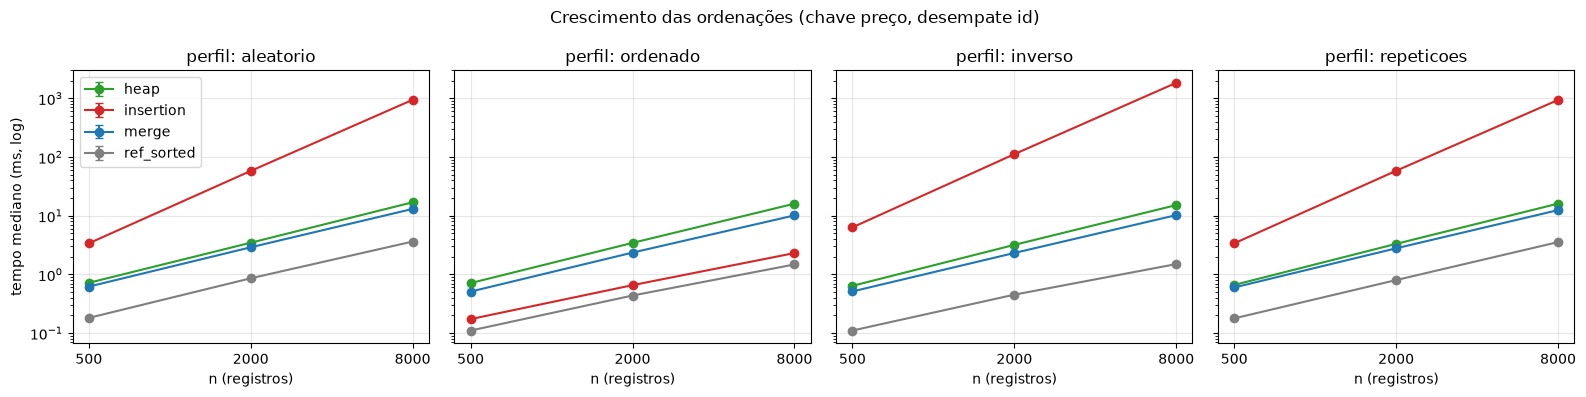

In [ ]:
ordc = graficos.ler("ordenacao")
r = graficos.resumo(ordc, "tempo", ["perfil", "estrategia", "n"])
r["mediana_ms"] = (r.mediana / 1e6).round(2)
r["iqr_ms"] = (r.iqr / 1e6).round(3)
display(r.pivot_table(index=["perfil", "estrategia"], columns="n", values=["mediana_ms", "iqr_ms"]))
graficos.grafico_ordenacao();

In [ ]:
ops = ordc[ordc.medida.isin(["comparacoes", "movimentacoes", "memoria_pico"])]
t = ops.pivot_table(index=["perfil", "estrategia"], columns=["medida", "n"], values="valor")
t

medida                comparacoes                        memoria_pico                      movimentacoes                       
n                            500        2000        8000         500       2000       8000          500        2000        8000
perfil     estrategia                                                                                                          
aleatorio  heap            7452.0    37681.0    182868.0      72792.0  288728.0  1158808.0        8120.0    40328.0    193398.0
           insertion      61915.0  1014612.0  15965016.0      72664.0  288600.0  1160504.0       61921.0  1014617.0  15965028.0
           merge           3858.0    19386.0     93739.0      73136.0  289264.0  1159472.0        4488.0    21952.0    103808.0
inverso    heap            7010.0    35964.0    176057.0      72792.0  288728.0  1158808.0        7352.0    37416.0    181552.0
           insertion     124750.0  1999000.0  31996000.0      72664.0  288600.0  1160480.0      125249.0  2000999.0  32003999.0
           merge           2216.0    10864.0     51456.0      73136.0  289264.0  1159472.0        4488.0    21952.0    103808.0
ordenado   heap            7756.0    39159.0    189377.0      72792.0  288728.0  1158808.0        8708.0    42600.0    205276.0
           insertion        499.0     1999.0      7999.0      72664.0  288600.0  1158680.0         499.0     1999.0      7999.0
           merge           2272.0    11088.0     52352.0      73136.0  289264.0  1159472.0        4488.0    21952.0    103808.0
repeticoes heap            7446.0    37719.0    182851.0      72792.0  288728.0  1158808.0        8102.0    40384.0    193250.0
           insertion      63245.0  1010639.0  15856863.0      72664.0  288600.0  1158680.0       63248.0  1010651.0  15856866.0
           merge           3850.0    19426.0     93585.0      73136.0  289264.0  1159472.0        4488.0    21952.0    103808.0

H1 se confirma. O Insertion Sort cresce ~16 vezes quando n quadruplica (aleatório: 3,4 → 58 → ~950 ms; inverso chega a
~1,9 s com 8000), como esperado de Θ(n²); as comparações batem com n²/4 no aleatório (16 milhões para n = 8000) e
n(n−1)/2 no inverso (32 milhões). Com entrada já ordenada ele faz n−1 comparações e é o mais rápido dos três (2,3 ms com
8000). Merge e heap crescem ~4,5 vezes por quadruplicação, compatível com n log n; o heap é ~25–60% mais lento que o merge
apesar de fazer o dobro de comparações, porque o sift-down acessa posições distantes e faz trocas de dois elementos. O
merge faz menos comparações em entrada ordenada ou inversa (o merge termina uma das metades antes), mas o mesmo número de
movimentações em qualquer perfil, por isso o tempo varia pouco. As repetições no preço não mudam nada: os empates são
desfeitos pelo id dentro da chave.

A memória de pico é praticamente a mesma nos três (~145 bytes por registro), porque é dominada pelos pares (chave,
registro) e pela lista de saída, que todos montam. As fatias do merge somam só n referências por nível e são liberadas
antes da lista de saída ser criada, então não aparecem no pico. Para o relatório (n ≈ 20 mil), insertion fica fora; merge
é o recomendado.

### 8.2 Buscas e distribuição dos ids (P3)

iqr_us                mediana_us                  
n                                          2000   6000    18000      2000     6000     18000
perfil      estrategia                                                                      
concentrada binaria/reconstroi-merge       0.037  0.074   0.008      1.003    1.308    1.352
            hash                           0.015  0.073   0.035      0.250    0.309    0.331
            interpolacao/reconstroi-merge  2.627  9.762  20.002    121.385  316.125  287.683
            ref_bisect                     0.002  0.019   0.012      0.248    0.319    0.298
            ref_dict                       0.002  0.012   0.022      0.093    0.113    0.114
            sequencial                     0.918  7.161  12.305     40.842  151.699  394.223
real        binaria/reconstroi-merge       0.017  0.023   0.022      0.989    1.176    1.355
            hash                           0.005  0.012   0.012      0.240    0.283    0.347
            interpolacao/reconstroi-merge  0.002  0.038   0.040      0.922    1.128    1.359
            ref_bisect                     0.006  0.002   0.005      0.257    0.303    0.356
            ref_dict                       0.001  0.005   0.005      0.097    0.109    0.134
            sequencial                     0.341  1.102   4.666     36.527  108.461  327.790
regular     binaria/reconstroi-merge       0.001  0.013   0.007      0.893    1.043    1.250
            hash                           0.007  0.008   0.009      0.181    0.211    0.306
            interpolacao/reconstroi-merge  0.020  0.003   0.008      0.290    0.306    0.350
            ref_bisect                     0.010  0.007   0.021      0.202    0.236    0.297
            ref_dict                       0.006  0.002   0.002      0.068    0.087    0.118
            sequencial                     0.442  1.659   5.529     33.171   99.308  293.026

medida                                     passos_max  passos_medio_acerto  passos_medio_erro
perfil      estrategia                                                                       
concentrada binaria/reconstroi-merge             15.0                 13.2               14.2
            hash                                  5.0                  1.3                0.5
            interpolacao/reconstroi-merge     16188.0                177.6             3125.1
            sequencial                        18000.0               9111.5            18000.0
real        binaria/reconstroi-merge             15.0                 13.2               14.2
            hash                                  5.0                  1.3                0.5
            interpolacao/reconstroi-merge        26.0                  5.8                5.6
            sequencial                        18000.0               9111.5            18000.0
regular     binaria/reconstroi-merge             15.0                 13.2               14.2
            hash                                  1.0                  1.0                0.5
            interpolacao/reconstroi-merge         1.0                  1.0                1.0
            sequencial                        18000.0               9111.5            18000.0

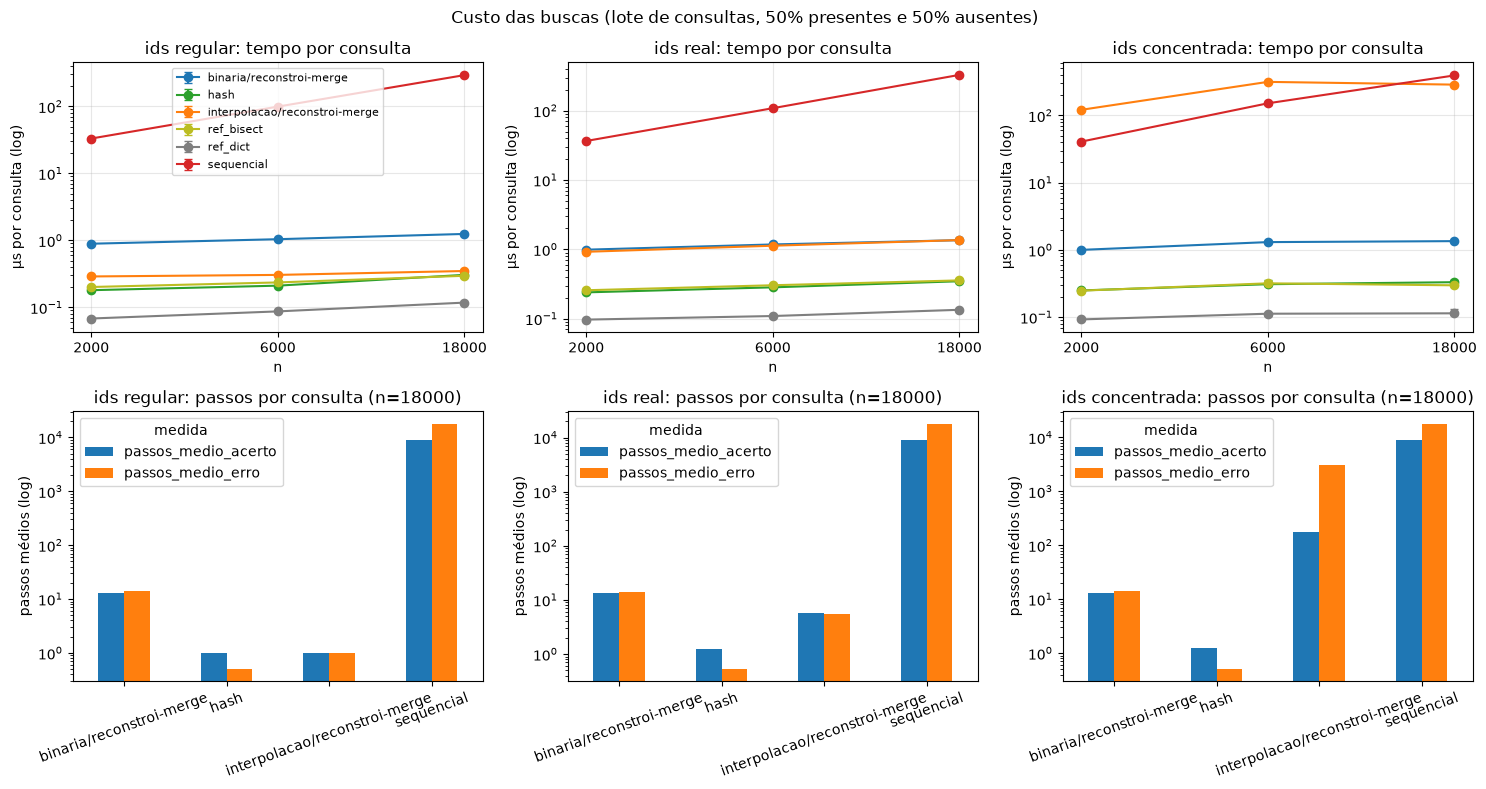

In [ ]:
busc = graficos.ler("busca")
r = graficos.resumo(busc, "tempo_por_consulta", ["perfil", "estrategia", "n"])
r["mediana_us"] = (r.mediana / 1e3).round(3)
r["iqr_us"] = (r.iqr / 1e3).round(3)
display(r.pivot_table(index=["perfil", "estrategia"], columns="n", values=["mediana_us", "iqr_us"]))
p = busc[busc.medida.isin(["passos_medio_acerto", "passos_medio_erro", "passos_max"]) & (busc.n == 18000)]
display(p.pivot_table(index=["perfil", "estrategia"], columns="medida", values="valor").round(1))
graficos.grafico_buscas();

Binária: ~13 passos com acerto e ~14 com erro para n = 18 000, igual a log₂ n, nas três distribuições. A sequencial faz
n/2 passos no acerto e n no erro, e o tempo cresce linearmente (de ~35 para ~330 µs por consulta).

H3 se confirma em parte. Com ids regulares a interpolação acerta na primeira sonda (1 passo) e é ~3,5 vezes mais rápida que
a binária. Com os ids reais do Airbnb ela faz ~6 sondas contra ~13 da binária, mas o tempo fica igual (~1,3 µs): cada
sonda custa mais (multiplicação, divisão inteira, mais leituras de `id`) e a vantagem em passos some. Com 10% de ids de 18
dígitos ela desaba: ~3 100 sondas por consulta sem sucesso e até 16 188 sondas no pior caso, quase n. O motivo é o
intervalo [menor id, maior id] ficar dominado pelos ids enormes; a estimativa cai sempre no começo do vetor e cada sonda
descarta poucas posições. Nesse cenário ela fica tão lenta quanto a sequencial (com n = 6000 chegou a ser mais lenta). A hash não liga para a distribuição
(~1,3 comparações no acerto e 0,5 no erro, ~0,3 µs).

### 8.3 Tabela hash e fator de carga (P4)

medida,capacidade_M,alfa_real,colisoes,baldes_vazios_pct,maior_balde,passos_medio_acerto,teoria_acerto,passos_medio_erro,teoria_erro,ns_consulta_mediana,ns_consulta_iqr,memoria_MB
parametro,,,,,,,,,,,,
alfa=0.25,79229.0,0.250,2307.0,77.918,4.0,1.126,1.125,0.245,0.250,227.792,7.919,5.709
alfa=0.5,39607.0,0.500,4269.0,60.782,5.0,1.247,1.250,0.500,0.500,212.704,4.135,3.067
alfa=0.75,26407.0,0.750,5895.0,47.336,6.0,1.380,1.375,0.752,0.750,256.027,44.750,2.144
alfa=1.0,19813.0,0.999,7168.0,36.234,7.0,1.494,1.500,0.998,0.999,210.475,98.767,1.690
alfa=2.0,9901.0,2.000,11243.0,13.554,9.0,1.981,2.000,1.993,2.000,252.238,23.148,0.931


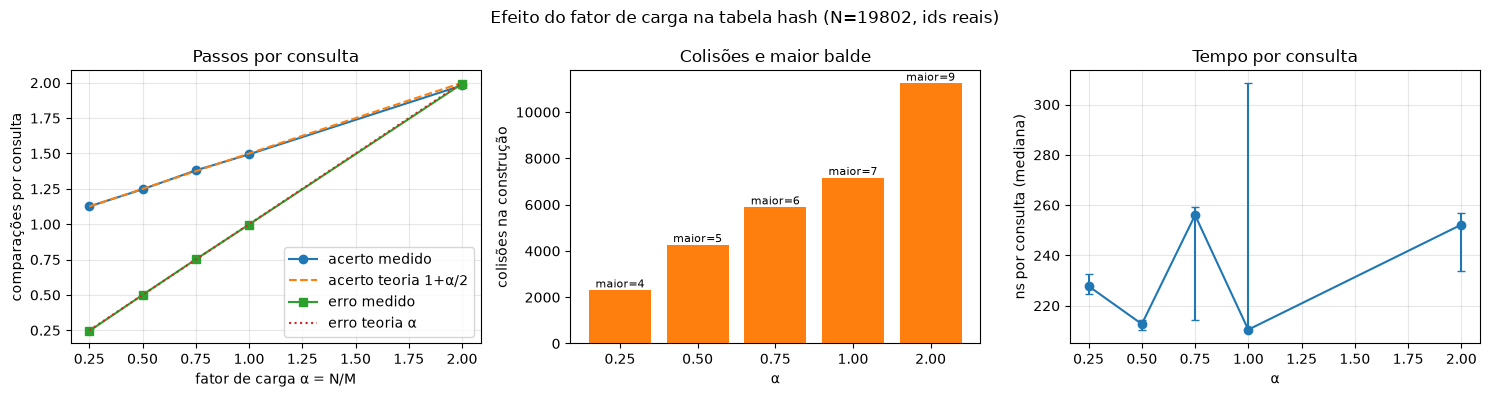

In [ ]:
hs = graficos.ler("hash")
tab = hs[hs.repeticao == 0].pivot_table(index="parametro", columns="medida", values="valor")
tt = graficos.resumo(hs, "tempo_por_consulta", ["parametro"]).set_index("parametro")
tab["ns_consulta_mediana"] = tt.mediana
tab["ns_consulta_iqr"] = tt.iqr
tab["memoria_MB"] = tab.memoria_construcao / 1e6
display(tab[["capacidade_M", "alfa_real", "colisoes", "baldes_vazios_pct", "maior_balde", "passos_medio_acerto",
             "teoria_acerto", "passos_medio_erro", "teoria_erro", "ns_consulta_mediana", "ns_consulta_iqr",
             "memoria_MB"]].round(3))
graficos.grafico_hash();

H4 se confirma: os passos medidos ficam em cima de 1 + α/2 (acerto) e α (erro) para todas as cargas, então id mod M com M
primo espalha os ids do Airbnb como uma função uniforme. As colisões na construção crescem com α (de ~2 300 para ~11 000)
e o maior balde vai de 4 para 9 elementos. O tempo por consulta quase não muda entre α = 0,25 e 1 (diferença de dezenas de
ns, perto do ruído): com no máximo 1,5 comparação por consulta, o custo é dominado por calcular o hash, achar o balde e
chamar o método. A memória vai no sentido oposto: α = 0,25 usa ~3,4 vezes mais que α = 1, porque cada balde é uma lista
Python vazia de 56 bytes. Para este uso, α entre 0,5 e 0,75 (o padrão do adaptador é preparar com 0,5 e fazer rehash
acima de 0,75) é um bom meio-termo.

### 8.4 Lote estático e ponto de compensação (P2)

In [ ]:
lt = graficos.ler("lote")
r = graficos.resumo(lt, "tempo_total", ["estrategia", "parametro"])
r["Q"] = r.parametro.str.replace("Q=", "").astype(int)
r["mediana_ms"] = (r.mediana / 1e6).round(3)
display(r.pivot_table(index="estrategia", columns="Q", values="mediana_ms"))

# modelo T_total(Q) = T_prep + Q * T_consulta com as medianas do experimento de busca (ids reais, n = 18000)
b = busc[(busc.perfil == "real") & (busc.n == 18000)]
prep = b[b.medida == "tempo_preparacao"].groupby("estrategia").valor.median()
cons = b[b.medida == "tempo_por_consulta"].groupby("estrategia").valor.median()
linhas = []
for est in prep.index:
    if est == "sequencial":
        continue
    q_eq = prep[est] / (cons["sequencial"] - cons[est])
    linhas.append({"estrategia": est, "T_prep_ms": prep[est] / 1e6, "T_consulta_us": cons[est] / 1e3,
                   "Q* contra sequencial": round(q_eq, 1)})
pd.DataFrame(linhas).round(3)

Q,1,10,100,1000,10000
estrategia,,,,,
binaria/reconstroi-merge,21.288,21.908,21.128,22.360,33.741
hash,4.957,5.580,5.568,5.312,7.132
interpolacao/reconstroi-merge,21.292,21.630,21.169,22.591,33.598
ref_bisect,1.295,1.281,1.345,1.564,3.835
ref_dict,0.927,0.941,0.915,1.006,1.662
sequencial,0.482,3.302,33.383,325.194,3386.989


,estrategia,T_prep_ms,T_consulta_us,Q* contra sequencial
0,binaria/reconstroi-merge,25.436,1.355,77.9
1,hash,5.476,0.347,16.7
2,interpolacao/reconstroi-merge,25.604,1.359,78.4
3,ref_bisect,3.633,0.356,11.1
4,ref_dict,1.656,0.134,5.1


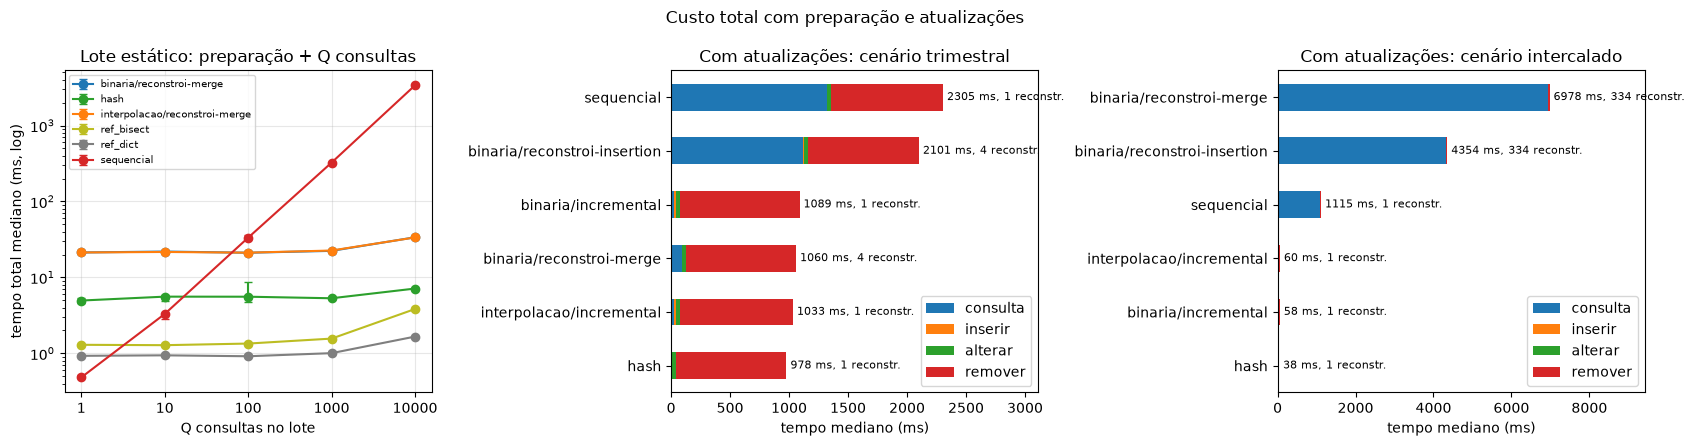

In [ ]:
graficos.grafico_custo_total();

H2 se confirma. Com a base inteira, a busca sequencial custa ~0,33 ms por consulta e a preparação da hash ~5 ms, então a
hash compensa a partir de ~17 consultas; a binária e a interpolação (preparar = ordenar por id com Merge Sort, ~21–25 ms)
compensam a partir de ~65–80 consultas. O lote medido concorda com o modelo: com Q = 10 a sequencial ainda ganha de todas
as nossas (3,3 ms contra 5 ms da hash), com Q = 100 já perde para todas (34 ms contra 5 e 21 ms). Até Q = 1000 o custo das
estruturas preparadas é quase só a preparação; com Q = 10 000 as consultas começam a aparecer (~10 ms a mais na binária).
O tempo de preparação no lote (base em ordem de id) é um pouco menor que no experimento de busca (amostra embaralhada)
porque o merge faz menos comparações em entrada ordenada.

### 8.5 Custo com atualizações (P5)

In [ ]:
ms = graficos.ler("misto")
partes = ["tempo_total", "tempo_consulta", "tempo_inserir", "tempo_alterar", "tempo_remover"]
r = ms[ms.medida.isin(partes)].groupby(["perfil", "estrategia", "medida"]).valor.median().unstack()[partes] / 1e6
iqr = graficos.resumo(ms, "tempo_total", ["perfil", "estrategia"]).set_index(["perfil", "estrategia"]).iqr / 1e6
r["iqr_total"] = iqr
r["reconstrucoes"] = ms[ms.medida == "reconstrucoes"].groupby(["perfil", "estrategia"]).valor.median()
r["respostas_iguais"] = ms[ms.medida == "respostas_iguais"].groupby(["perfil", "estrategia"]).valor.min()
print(ms.drop_duplicates("perfil")[["perfil", "parametro"]].to_string(index=False))
r.round(1)

     perfil                                             parametro
 trimestral consulta=4000;inserir=4341;alterar=30810;remover=5619
intercalado     consulta=3224;inserir=181;alterar=399;remover=196


medida                                    tempo_total  tempo_consulta  tempo_inserir  tempo_alterar  tempo_remover  iqr_total  \
perfil      estrategia                                                                                                          
intercalado binaria/incremental                  58.4            25.7            0.6            0.5           31.5        0.6   
            binaria/reconstroi-insertion       4353.8          4322.3            0.2            0.8           30.7       56.3   
            binaria/reconstroi-merge           6977.6          6945.7            0.3            1.0           30.8      104.5   
            hash                                 37.6             6.1            0.2            0.6           30.7        0.3   
            interpolacao/incremental             60.3            27.3            0.6            0.6           31.5        0.2   
            sequencial                         1115.5          1083.2            0.3            1.0           30.9        3.8   
trimestral  binaria/incremental                1093.0            27.2           16.2           32.5         1013.0       62.8   
            binaria/reconstroi-insertion       2101.0          1122.0            3.0           32.3          943.6       99.5   
            binaria/reconstroi-merge           1060.2            88.5            3.0           31.8          936.3       11.1   
            hash                                977.3             7.2            4.1           31.1          935.3       10.2   
            interpolacao/incremental           1034.1            27.3           16.0           32.0          958.1        7.4   
            sequencial                         2294.9          1322.1            2.9           32.2          948.0       55.5   

medida                                    reconstrucoes  respostas_iguais  
perfil      estrategia                                                     
intercalado binaria/incremental                     1.0                 1  
            binaria/reconstroi-insertion          334.0                 1  
            binaria/reconstroi-merge              334.0                 1  
            hash                                    1.0                 1  
            interpolacao/incremental                1.0                 1  
            sequencial                              1.0                 1  
trimestral  binaria/incremental                     1.0                 1  
            binaria/reconstroi-insertion            4.0                 1  
            binaria/reconstroi-merge                4.0                 1  
            hash                                    1.0                 1  
            interpolacao/incremental                1.0                 1  
            sequencial                              1.0                 1

Todas as estratégias deram exatamente as mesmas respostas, consulta a consulta, nos dois cenários e nas 5 repetições
(`respostas_iguais` = 1), incluindo consultas a anúncios que já tinham sido removidos.

Cenário intercalado (H5 confirmada): reconstruir a cópia ordenada depois de cada inserção ou remoção é a pior escolha.
Foram 334 reconstruções e ~7 s com Merge Sort, mais de 6 vezes o custo de não ter índice nenhum (sequencial, ~1,1 s).
Manter a cópia ordenada de forma incremental (busca binária da posição + `insert`/`del`) custa ~60 ms no total, e a hash
~38 ms, a melhor. A interpolação incremental fica igual à binária, porque os ids reais são quase uniformes.

Cenário trimestral: o resultado não era o esperado. Aqui 88–96% do tempo das estratégias com índice é a remoção na
lista principal do repositório (5 619 remoções, cada uma achando a posição por varredura O(n) e deslocando a lista com
`del`), que é igual para todas. Por isso hash, incremental e binária que reconstrói com Merge Sort ficam todas em ~1,0–1,1 s:
são só 4 reconstruções. A sequencial dobra (~2,3 s) porque as 4 000 consultas custam O(n) cada. A surpresa foi a binária
que reconstrói com Insertion Sort: a ideia era aproveitar que a lista principal fica quase ordenada por id, mas ~45% dos
anúncios novos têm id menor que o maior existente, cada um precisa andar milhares de posições, e cada reconstrução custou
~280 ms contra ~23 ms do Merge Sort. A inserção incremental também custa mais no lote trimestral (~16 ms contra ~3 ms)
porque cada `insert` no meio desloca a lista.

A lição para o sistema é que, com atualização em lote, a escolha do índice importa pouco e o gargalo é a remoção da
coleção principal; com atualização intercalada, reconstruir é proibitivo e é preciso manutenção incremental ou hash.

### 8.6 Comparação com referências nativas

In [ ]:
def razao(df, medida, nossa, ref, filtro):
    d = df[(df.medida == medida) & filtro(df)]
    med = d.groupby("estrategia").valor.median()
    return med[nossa] / med[ref]

linhas = [
    {"operação": "ordenar 8000 aleatórios", "nossa": "merge", "nativa": "sorted (Timsort em C)",
     "nossa/nativa": razao(ordc, "tempo", "merge", "ref_sorted", lambda d: (d.n == 8000) & (d.perfil == "aleatorio"))},
    {"operação": "consulta por id, n = 18000 reais", "nossa": "hash", "nativa": "dict",
     "nossa/nativa": razao(busc, "tempo_por_consulta", "hash", "ref_dict", lambda d: (d.n == 18000) & (d.perfil == "real"))},
    {"operação": "consulta por id, n = 18000 reais", "nossa": "binária", "nativa": "bisect",
     "nossa/nativa": razao(busc, "tempo_por_consulta", "binaria/reconstroi-merge", "ref_bisect", lambda d: (d.n == 18000) & (d.perfil == "real"))},
    {"operação": "preparar índice, n = 18000 reais", "nossa": "hash", "nativa": "dict",
     "nossa/nativa": razao(busc, "tempo_preparacao", "hash", "ref_dict", lambda d: (d.n == 18000) & (d.perfil == "real"))},
]
pd.DataFrame(linhas).round(1)

,operação,nossa,nativa,nossa/nativa
0,ordenar 8000 aleatórios,merge,sorted (Timsort em C),3.6
1,"consulta por id, n = 18000 reais",hash,dict,2.6
2,"consulta por id, n = 18000 reais",binária,bisect,3.8
3,"preparar índice, n = 18000 reais",hash,dict,3.3


As rotinas nativas são de 2,5 a 4 vezes mais rápidas. `sorted`, `dict` e `bisect` rodam em C, sem interpretar cada
comparação e sem chamar property; nossas versões fazem o mesmo trabalho assintótico em laços Python. O `bisect` ainda
procura numa lista de inteiros, enquanto a nossa binária lê `v[meio].id` (acesso a atributo) a cada passo. O `sorted` é
Timsort, que aproveita trechos já ordenados (no perfil ordenado ele fica ~7 vezes mais rápido que o merge). Isso muda a
constante, não a classe de complexidade: as curvas têm a mesma inclinação nos gráficos log-log.

## 9. Recomendação

Para o serviço de consulta da fiscalização (muitas consultas por id, base de ~20 mil anúncios atualizada por coletas):

1. Usar a tabela hash própria como estrutura de consulta por id, preparada com α ≈ 0,5 e rehash acima de 0,75. Ela se
   paga a partir de ~17 consultas, responde em ~0,3 µs, não depende da distribuição dos ids e se atualiza a cada
   inserção ou remoção sem reconstruir. É o melhor resultado nos dois cenários com atualização.
2. Se também for preciso percorrer anúncios em ordem de id (faixas de ids, vizinhos), manter a cópia ordenada de forma
   incremental, com busca binária. Nunca reconstruir a cada mudança se atualizações e consultas se intercalam.
3. Não usar busca por interpolação: com os ids de 2021 ela não ganha da binária em tempo, e com os ids de 18 dígitos que o
   Airbnb usa hoje ela vira quase linear. A base real já vai ter essa mistura nas coletas a partir de 2022.
4. Para o relatório por preço, Merge Sort (Θ(n log n) em qualquer perfil, estável). Heapsort se memória auxiliar for
   restrição; Insertion Sort só se a entrada já vier ordenada.
5. O próximo gargalo é a remoção na lista principal (O(n) por remoção). Num lote trimestral com ~5 600 remoções ela custa
   ~1 s, mais que todo o resto. Melhorias possíveis: marcar como removido e compactar a lista uma vez por lote, ou
   remover em lote reconstruindo a lista uma vez.

A recomendação muda se: a base crescer para milhões de anúncios (a memória da hash com listas por balde pesa, e uma
cópia ordenada ocupa menos); as consultas forem poucas por coleta (menos de ~15, a sequencial basta); for preciso
consulta por intervalo de id (a hash não serve); ou se os ids voltassem a ser regulares, caso em que a interpolação passa a
valer a pena.

## 10. Limitações

- Os tempos são de uma máquina (Apple, CPython 3.14) e de uma sessão; semente fixa não elimina variação do sistema.
  O IQR foi pequeno na maioria das medidas, mas na hash a diferença entre cargas está perto do ruído.
- Contagens e memória vêm de uma repetição (a 0). `tracemalloc` só mede alocações do Python dentro da chamada.
- Os lotes de busca são de 2000 consultas; para as estratégias rápidas isso dá ~1 ms de medição, o que é sensível a ruído
  (no experimento da hash ampliamos para 20 000).
- A distribuição "concentrada" é sintética: misturamos 10% de ids de 18 dígitos para imitar o formato atual do Airbnb,
  mas a proporção real depende da coleta.
- As consultas ausentes são ids vizinhos de ids existentes ou já removidos; ids completamente fora do intervalo seriam
  mais baratos para interpolação e binária.
- O cenário intercalado usa proporções escolhidas por nós (80/10/5/5), não medidas de um serviço real.
- Os bairros perderam os acentos na fonte e não foram corrigidos; a nota mudou de escala entre coletas e a conversão de
  0–100 para 0–5 supõe que as duas escalas medem a mesma coisa.
- Não implementamos Quick Sort nem as buscas por salto, exponencial e indexada.

## 11. Referências

- Inside Airbnb, Lisbon listings 2021. http://insideairbnb.com/get-the-data (CC BY 4.0).
- maurylukas, "2021 Lisbon Airbnb Data", Kaggle. https://www.kaggle.com/datasets/maurylukas/listings (CC BY 4.0).
- Cormen, Leiserson, Rivest, Stein. Introduction to Algorithms, 3ª ed. (ordenação, heap, hash, recorrências).
- Materiais da disciplina: complexidade e recorrências, ordenação, busca e hash, busca interna avançada, heap e heapsort.
- Código reaproveitado dos nossos exercícios: merge com fatias (Exercícios 05) e hash por divisão (Exercícios 06),
  adaptados para pares (chave, registro), contadores e classes.
- Bibliotecas: pandas, NumPy e matplotlib (versões em `resultados/ambiente.txt` e `requirements.txt`), pytest.

## 12. Contribuição dos integrantes

| integrante | contribuição |
|---|---|
| Alexandre dos Santos Gualberto | Implementação e testes das estruturas e algoritmos: ordenações, buscas, tabela hash, repositório orientado a objetos e demonstração do sistema. |
| Luiz Venâncio Jaldin de Oliveira | Planejamento e execução dos experimentos; análise de métricas, gráficos, interpretação dos resultados, recomendação técnica e documentação no notebook. |
| Alessandro | 	Obtenção, limpeza, validação, documentação e exportação dos dados; manutenção dos CSVs, logs de transformação e ambiente reproduzível. |

Uso de ferramentas de apoio: O Claude foi usado como suporte para criação dos códigos e estruturação do projeto, e o ChatGPT foi utilizando para ler o contéudo do projeto e confrontar com os requisitos para validar se exisita alguma pendência.